<a href="https://colab.research.google.com/github/KgadiKatse/reinforcement_learning/blob/main/Industrial_Q_Learning_Exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Q-Learning for Autonomous Navigation in Simple Mining Environments
### *A Hands-On, Interactive Guide to Reinforcement Learning for application in Industrial Robotics - An example in a simple mining environment*

---

**Reinforcement Learning: Q-Learning**

| | |
|---|---|
| **Exercise Context** | Mining - Haul Trucks |
| **Algorithm** | Q-Learning (model-free, off-policy TD control) |
| **Use case** | Autonomous vehicle navigation in a open-pit mine grid |
| **Level** | Beginner → Intermediate |

---

## 📌 What this notebook covers

1. **Why Q-Learning matters for mining** — real-world context and business value
2. **The environment** — how we model a mine as a grid-world
3. **The Q-Learning algorithm** — the theory explained step by step
4. **Implementation** — every function explained, annotated, and unit-tested inline
5. **Interactive training** — sliders to tune hyperparameters and watch the agent learn *live*
6. **Visual diagnostics** — heatmaps, learned policy arrows, learning curves
7. **Validation metrics** — how to know if the trained agent is actually good enough to deploy
8. **From notebook to production** — the tech stack that could be needed to run this on a real autonomous vehicle
9. **Limitations & next steps** — where tabular Q-Learning breaks down, and what comes after

> 💡 **How to use this notebook:** Run the cells top to bottom once. Then go back to the
> **"🎛️ Interactive Lab"** section and play with the sliders — you don't need to touch a
> single line of code to explore how each hyperparameter changes the agent's behavior.



## 1. Why Q-Learning, and why mining? 🏗️

### The business problem
Modern mining and bulk-logistics operations increasingly rely on **autonomous haulage
vehicles** (AHVs) — driverless trucks, trains, and loaders that move ore, waste rock, or
inventory between fixed points (a pit face, a stockpile, a crusher, a loading dock) without
a human driver in the cab.

Two flagship real-world examples:

- **Rio Tinto's AutoHaul** — the world's first fully autonomous heavy-haul long-distance
  train network, running across ~1,700 km of track in the Pilbara region of Western
  Australia, connecting 16 mines to 4 port terminals.
- **Komatsu FrontRunner / Rio Tinto Autonomous Haulage System (AHS)** — fleets of 100+
  autonomous haul trucks that have collectively moved **billions of tonnes** of material
  without a human driver, guided by a supervisory control system.

These systems don't (yet) use raw tabular Q-Learning at production scale — they combine GPS,
LiDAR, radar, and rule-based planners — but the **core decision-making problem they solve is
exactly what Q-Learning teaches us to solve**:

> *"Given my current position and the layout of hazards/obstacles around me, which direction
> should I move next to reach my destination safely and efficiently — and how do I learn this
> policy purely from experience, without being told the 'right' answer in advance?"*

### Why Q-Learning is a great *starting point* (before jumping to production-grade AHS)

| Reason | Explanation |
|---|---|
| **Model-free** | The agent doesn't need a hand-built physics/geometry model of the mine — it learns purely from trial-and-error interaction, just like early-stage AHS calibration on a new pit layout. |
| **Interpretable** | The learned "Q-table" is just a lookup table of numbers you can print, plot, and audit — critical for safety sign-off in a mining environment. |
| **Cheap to prototype** | You can simulate an entire haul-road network layout change in seconds on a laptop before ever touching real machinery. |
| **Transferable concepts** | The exploration/exploitation trade-off, reward shaping, and convergence diagnostics you learn here directly generalize to the Deep RL and path-planning stacks used in real AHS software. |

### The concrete task in this notebook
We simulate a **14 × 15 grid map** of a mine/warehouse floor. The autonomous agent (think:
a scaled-down haul truck or an automated guided vehicle, AGV) starts at a depot and must
learn — purely through repeated trial runs — the safest, shortest route to a **loading /
dumping point**, while avoiding **hazard zones** (modeling shelving racks, restricted
blast zones, pit walls, or no-go safety exclusion areas around other equipment).


# Mining Haul Trucks: Overview and Emerging Technologies

![Alt text](https://www.sibo.eu/wp-content/uploads/2026/02/Dump-Truck-Types-On-Road-Articulated-Underground-and-Rigid.jpg)

Mining haul trucks are specialized, off-highway vehicles engineered to transport massive payloads of rock, ore, and overburden across both surface and underground operations. Depending on terrain, payload requirements, and mine design, these vehicles are selected to optimize hauling efficiency.

## Conventional Haul Truck Classifications

| Dump Truck Type | Design | Capacity | Optimal Use |
| :--- | :--- | :--- | :--- |
| **Rigid Frame Mining Trucks** | Single, continuous, heavy-duty steel frame designed for maximum structural integrity. | 90 to >400 tons (ultra-class) | Large-scale, high-production open-pit mines with wide, well-maintained, and compacted haul roads. |
| **Articulated Dump Trucks (ADTs)** | Pivoting hinge joint between the cab and the dump body, paired with all-wheel drive. | 25 to 60 tons | Rough, soft, muddy, or steep topographies where rigid-frame trucks cannot maintain traction. |
| **Underground Haul Trucks** | Low-profile, highly compact, and narrow structures. | 30 to 60 metric tons | Underground mining and tunneling operations characterized by tight turning radii and low ceilings. |

---

## Specialized & Emerging Technologies

As the mining industry pushes toward zero-emission and high-efficiency operations, specialized truck variants are becoming standard:

*   **Battery-Electric & Trolley-Assist:** These vehicles utilize high-capacity battery architectures or overhead electric trolley lines. They are designed to eliminate greenhouse gas emissions, significantly reduce the need for underground ventilation, and lower overall energy costs.
*   **Tracked Dump Trucks:** Rather than using traditional pneumatic tires, these trucks are equipped with continuous tracks to distribute weight evenly across ultra-soft, swampy, or highly unstable ground.
*   **Autonomous Haulage Systems (AHS):** Driverless fleets guided by GPS, LiDAR, and centralized dispatch systems. They enable continuous 24/7 operation and remove human operators from hazardous zones.

### Modeling Autonomous Workability via Reinforcement Learning

The operational viability of Autonomous Haulage Systems (AHS) can be effectively modeled, tested, and optimized using **Reinforcement Learning (RL)** algorithms. RL allows an agent (the truck) to learn optimal behaviors through trial and error within a simulated mining environment.

*   **Tabular Q-Learning:** For early-stage validation or simplified models, the mine site can be discretized into a grid-world. Using Tabular Q-Learning, the truck learns a policy to navigate from the loading unit (e.g., an excavator) to the dump site. The algorithm updates a Q-table based on rewards (e.g., +100 for reaching the crusher, -10 for unnecessary delays, -100 for collisions), teaching the truck the most efficient route while avoiding static obstacles.
*   **Deep Reinforcement Learning (DRL):** Real-world mine environments have continuous state spaces (exact coordinates, varying speeds, dynamic obstacles like other trucks). To demonstrate workability in these complex scenarios, algorithms like **Deep Q-Networks (DQN)** or **Proximal Policy Optimization (PPO)** are utilized. These neural-network-backed algorithms can ingest high-dimensional sensor data (simulated LiDAR/camera inputs) to make real-time decisions on steering, acceleration, and braking, ensuring safe and efficient fleet interactions.

By simulating these trucks in an RL environment, mining engineers can prove the safety and efficiency of automated dispatch algorithms before deploying physical assets to the pit.

In this example, we shall be simulating a Tabular Q-learning model for our simple mining environment.


## 2. Setup — Libraries & Tech Stack 🧰

We keep the dependency footprint intentionally small — this is one of Q-Learning's biggest
practical advantages over Deep RL. Everything below runs comfortably on a laptop CPU, with
no GPU required.

| Library | Role in this notebook | Role in a production AHS stack |
|---|---|---|
| `numpy` | Q-table storage & vectorized math | Same — or replaced by a tensor library (PyTorch/TensorFlow) if the policy is a neural net |
| `matplotlib` / `seaborn` | Visualizing the grid, learned policy, and learning curves | Fleet-management dashboards, telemetry visualization |
| `pandas` | Tabulating metrics for validation | Data pipelines / MLOps monitoring (e.g., Grafana, MLflow) |
| `ipywidgets` | Interactive sliders for hyperparameter exploration | Engineer-facing tuning consoles / digital twins |
| `random` / `collections` | Utility sampling & BFS ground-truth check | Route-planning validation suites |

> 🧪 We install/import everything up front so the notebook is fully reproducible top-to-bottom.


In [16]:
# ── ENVIRONMENT SET UP────────────────────────────────────────────────────────

# ── Core libraries ───────────────────────────────────────────────────────────
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.colors import ListedColormap
from collections import deque

# ── Interactivity ────────────────────────────────────────────────────────────
# ipywidgets lets us build slider-driven "what-if" experiments without
# re-writing code -- this is what makes the notebook genuinely interactive.
import ipywidgets as widgets
from ipywidgets import interact, interact_manual, FloatSlider, IntSlider, Dropdown
from IPython.display import display, HTML, clear_output

# ── Reproducibility ──────────────────────────────────────────────────────────
# Fixing the seed means everyone who runs this notebook sees the same
# training curves and final policy -- essential for teaching AND for
# regression-testing a real navigation stack.
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("✅ Libraries loaded. NumPy:", np.__version__, "| Pandas:", pd.__version__)


✅ Libraries loaded. NumPy: 2.1.3 | Pandas: 2.2.3



## 3. Modeling the Mine as a Grid-World 🗺️

We represent our simple mining pit as a **discrete grid** of `14 rows × 15 columns`.
This is big enough for 5 benches and 4 switchbacks, and small enough for a tabular Q-table.

`Cells: 14 × 15 = 210`

`Q-table: 210 cells × 2 load states × 5 actions (N, S, E, W and Wait) = 2,100 entries.`

> Wait has to exist for the delay penalty to mean anything.

Only 220 states are actually reachable, because walls and hazards are terminal.

Each bench has a 1-cell-wide road. The switchbacks are 2 cells wide and 2 rows tall. The top and bottom benches are open yards, 2 rows each.

This is a classic and powerful simplification technique in robotics called **grid-world discretization** — real GPS/LiDAR coordinates get "snapped" onto a coarse grid so that classical tabular RL becomes tractable.

### Anatomy of a state
Every cell `(row, col)` falls into exactly one of the following categories:

| Cell type | Meaning in a mine/warehouse | Reward given for entering it |
|---|---|---|
| 🟩 **Goal_1** | The crusher — the agent's destination when loaded | Large **positive** reward |
| 🟨 **Goal_2** | The loading point — the agent's destination when empty | Large **positive** reward |
| 🟥 **Hazard Zone** | The exclusion zones, pit walls, blast zones, other vehicles' safety radius | Large **negative** reward (terminates the episode — think like "the vehicle stops" or "an incident is logged") |
| ⬜ **Free Haul Road** | Safe, drivable ground | Small **negative** reward (a small cost per step — this is what nudges the agent toward the *shortest* safe path, since dawdling costs money: fuel, time, wear) |
| 🟦 **Parking Bay** | Safe spot for parking | No reward. A **negative** reward obtained when truck stalls (a penalty to prevent truck from learning to sit at the bay, so making it a start state only) |

⚙️ **Design choice**

> - The hazards sit on half the ramp width rather than blocking it. That forces the truck to learn lane discipline at the bends instead of finding the road permanently closed.
> - state = (row, col, load), where load is 0 (empty) or 1 (loaded).
> - The load flag decides which goal is live.
> > - Empty: the goal is the loader.
> > - Loaded: the goal is the crusher.
> - The same grid cell has different Q-values in each load layer. For example, the road at (4,6) means “go down the pit” when empty and “go up out of the pit” when loaded.
> Terminal states are wall, construction, transformer, and any collision.
Goal states are not terminal. Reaching one gives +100 and flips the load flag, which creates the loop.

🌀 **Making the loop continuous**
> - At the loader with load = 0: +100, then the load flag flips to 1.
> - At the crusher with load = 1: +100, then the load flag flips to 0.
> - At the loader while loaded, or the crusher while empty: no bonus, and a -10 delay penalty.

> Because the +100 only pays out when the flag flips, the truck can’t farm reward by hovering near a goal. It has to complete the full trip. This also removes the need for a separate bonus.

 🏁 **Why implementing a richer reward signal will help**
> - One of the most important levers in real-world RL engineering: a *sparse* reward (only non-zero at the goals) makes learning painfully slow because the agent gets almost no feedback until it stumbles onto the goal by pure luck.
> - A **shaped, dense reward** teaches the agent "closer/faster is better" and "hazards are costly" on *every single step*, which is exactly the kind of signal a safety-critical mining system needs.



In [2]:

# ── Grid dimensions ──────────────────────────────────────────────────────────
ENV_ROWS = 15     # north-south extent of the mine floor
ENV_COLS = 15     # east-west extent of the mine floor

# ── Actions the agent can take ───────────────────────────────────────────────
# Numeric action codes: 0 = up, 1 = right, 2 = down, 3 = left, 4 = wait
ACTIONS = ['up', 'right', 'down', 'left', 'wait']
N_ACTIONS = len(ACTIONS)
UP, RIGHT, DOWN, LEFT, WAIT = range(N_ACTIONS)
ACTION_DELTAS = [(-1, 0), (0, 1), (1, 0), (0, -1), (0, 0)]   # (d_row, d_col)
ARROWS = ['^', '>', 'v', '<', 'o']

# ── Load state (second half of the state) ────────────────────────────────────
EMPTY, LOADED = 0, 1
LOAD_NAMES = ['empty', 'loaded']

# ── Key locations ────────────────────────────────────────────────────────────
START_STATE   = (0, 10)    # Top parking bay (bench 1), start state only
CRUSHER_STATE = (0, 3)     # Goal when loaded
LOAD_STATE    = (14, 11)   # Loader, goal when empty
PARKING_BAY   = (0, 10)

print(f"Grid size: {ENV_ROWS} rows x {ENV_COLS} columns = {ENV_ROWS*ENV_COLS} states")
print(f"Start (Parking Bay):        {START_STATE}")
print(f"Goal 1 when truck is loaded:   {CRUSHER_STATE}")
print(f"Goal 2 when truck is empty:   {LOAD_STATE}")
print(f"The Parking Bay on the top bench {PARKING_BAY}")


Grid size: 15 rows x 15 columns = 225 states
Start (Parking Bay):        (0, 10)
Goal 1 when truck is loaded:   (0, 3)
Goal 2 when truck is empty:   (14, 11)
The Parking Bay on the top bench (0, 10)


In [3]:

# ── Pit Map with Hazard zones (hazards, haul road, switchbacks, parking bay)) ───────
#   - equipment exclusion zones (safety radius around excavators/shovels/crusher/transformer + buildings)
#   - blast zones with active charges
#   - unstable pit walls/berms
#   - restricted haul-road segments (one-way sections, weight limits)

# We store them as {row_index: [list of column_indices]} for readability,
# then flatten into a fast lookup set of (row, col) tuples.

# Every hazard is terminal (-100). Anything not listed is free haul road/yard.
# Row 0 = top (bench 1), row 14 = bottom (bench 5).
hazard_zones = {}

# Switchback 1 (east, clear): pit wall, ramp open on cols 12-13
hazard_zones[2]  = list(range(0, 12))              # cols 0..11

# Switchback 2 (west): construction area on col 0, pit wall on cols 2..13
hazard_zones[5]  = [0] + list(range(2, 15))        # col 0 + cols 2..14

# Switchback 3 (east): pit wall on cols 0..11, transformer + buildings on col 13 and 14
hazard_zones[8]  = list(range(0, 12)) + [13] + [14]     # cols 0..11 + col 13..14

# Switchback 4 (west, clear): pit wall, ramp open on cols 0-1
hazard_zones[11] = list(range(2, 15))              # cols 2..13

# Blast Reserve next to loader: pit wall and blast reserve east of loader
hazard_zones[12] = list(range(11, 15))              # cols 11..15
hazard_zones[13] = list(range(12, 15))              # cols 12..15
hazard_zones[14] = list(range(12, 15))              # cols 12..15

HAZARD_CELLS = {(r, c) for r, cols in hazard_zones.items() for c in cols}

# Sanity checks: the map must be consistent with the constants above
assert all(0 <= r < ENV_ROWS and 0 <= c < ENV_COLS for r, c in HAZARD_CELLS)
for name, cell in [("start", START_STATE), ("crusher", CRUSHER_STATE),
                   ("loader", LOAD_STATE), ("parking bay", PARKING_BAY),
                   ]:
    assert 0 <= cell[0] < ENV_ROWS and 0 <= cell[1] < ENV_COLS, f"{name} is off the grid"
    assert cell not in HAZARD_CELLS, f"{name} sits on a hazard cell"

n_hazard = len(HAZARD_CELLS)
print(f"Grid size: {ENV_ROWS} rows x {ENV_COLS} columns = {ENV_ROWS * ENV_COLS} cells")
print(f"Hazard cells: {n_hazard}   Free cells: {ENV_ROWS * ENV_COLS - n_hazard}")
print(f"Start (parking bay):          {START_STATE}")
print(f"Crusher (goal when loaded):   {CRUSHER_STATE}")
print(f"Loader (goal when empty):     {LOAD_STATE}")
print(f"Parking bay:                  {PARKING_BAY}")
print(f"Hazard cells per row:         { {r: len(c) for r, c in sorted(hazard_zones.items())} }")


Grid size: 15 rows x 15 columns = 225 cells
Hazard cells: 63   Free cells: 162
Start (parking bay):          (0, 10)
Crusher (goal when loaded):   (0, 3)
Loader (goal when empty):     (14, 11)
Parking bay:                  (0, 10)
Hazard cells per row:         {2: 12, 5: 14, 8: 14, 11: 13, 12: 4, 13: 3, 14: 3}


In [4]:
# ── Reward function ──────────────────────────────────────────────────────────
# These constants are exactly the "reward shaping" levers a mining-automation
# engineer would tune when the vehicle behaves too cautiously (raise STEP_COST magnitude) or
# too recklessly around hazards (raise COLLISION_PENALTY magnitude).
STEP_COST         = -1     # every ordinary move
DELAY_PENALTY     = -10    # wait, immediate backtrack, or wrong goal
COLLISION_PENALTY = -100   # wall, construction, transformer, off-grid (terminal)
GOAL_REWARD       = 100    # loader while empty, crusher while loaded
CYCLE_BONUS       = 50     # extra, paid on the crusher dump (completed haul)
MAX_STEPS         = 300    # episode truncation

In [5]:
# Pre-compute the list of "safe, non-terminal" cells -- useful later for
# exploring-starts training and for robustness testing.
FREE_CELLS = [
    (r, c) for r in range(ENV_ROWS) for c in range(ENV_COLS)
    if (r, c) not in HAZARD_CELLS and (r, c) != CRUSHER_STATE and (r, c) != LOAD_STATE
]
print(f"Free (safe, drivable) cells: {len(FREE_CELLS)} out of {ENV_ROWS*ENV_COLS} total")

Free (safe, drivable) cells: 160 out of 225 total


### 🖼️ Visualizing the mine layout

Our process will involve:
1. Loading at the loader (excavator/shovel)
2. Hauling the material on free haul road and avoiding collisions
3. Dumping the load at the crusher
4. Returning to the Loader

Which looks a little like this:

![Alt text](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQ1JU5Y-ymPa8XHgU25DKQ7T_0PnL4DLd2lX67Ah7FLss56hpKVSd9bMkA&s=10)

Before training anything, we must always **look at our environment**.

This single habit catches more bugs (unreachable goals, disconnected hazard zones, off-by-one grid errors) than any amount of code review.

We need to see our mine map in detailed, the benches, the switchbacks and the other obstacles we have placed in different areas for our haul truck to avoid.


In [6]:
# Numeric cell codes used only for drawing
FREE, HAZARD, CRUSHER, LOADER, BAY = range(5)
MAP_COLORS = ["#f4f4f4",   # 0 free haul road
              "#c62828",   # 1 hazard zone
              "#2e7d32",   # 2 crusher (green)
              "#ef6c00",   # 3 loader (orange)
              "#1565c0"]   # 4 parking bay (blue)

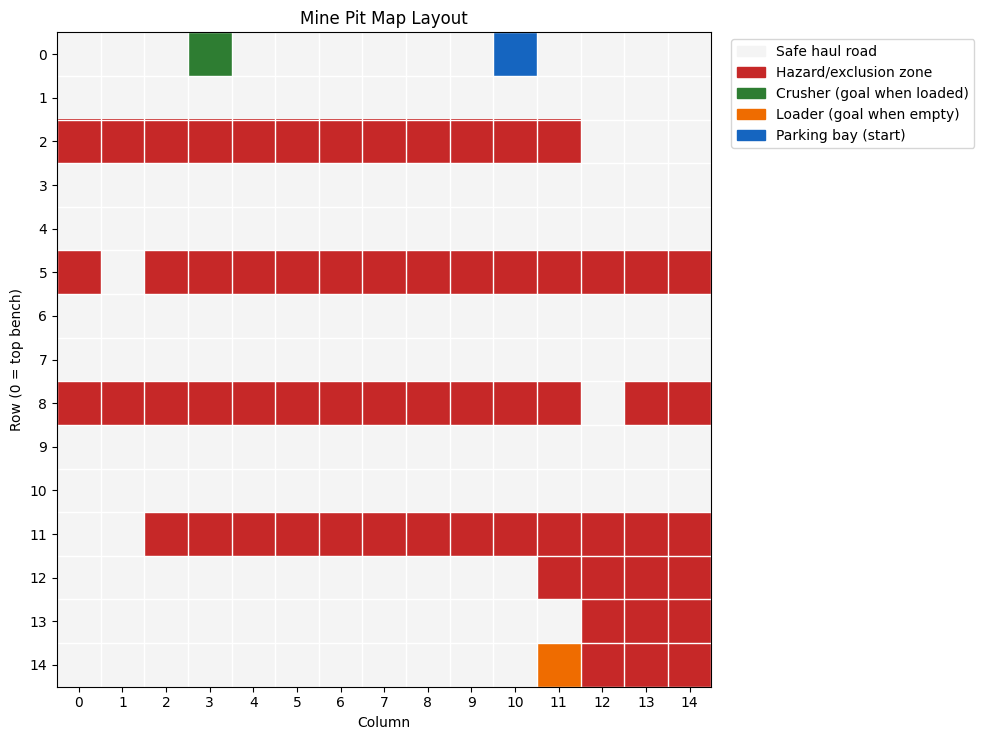

In [12]:
def map_legend_handles():
    """Legend patches for the pit map (shared by render_grid and the two-map figure)."""
    return [
        mpatches.Patch(color=MAP_COLORS[FREE],    label="Safe haul road"),
        mpatches.Patch(color=MAP_COLORS[HAZARD],  label="Hazard/exclusion zone"),
        mpatches.Patch(color=MAP_COLORS[CRUSHER], label="Crusher (goal when loaded)"),
        mpatches.Patch(color=MAP_COLORS[LOADER],  label="Loader (goal when empty)"),
        mpatches.Patch(color=MAP_COLORS[BAY],     label="Parking bay (start)"),
    ]


def render_grid(highlight_path=None, title="Mine Pit Map Layout", ax=None,
                route_color="#6a1b9a", route_label="Agent route",
                show_direction=False, legend=True):
    """Draw the pit: hazards (red), crusher (green), loader (orange),
    parking bay (blue) and the free haul road (white/grey).

    Parameters
    ----------
    highlight_path : list[(row, col)] or None
        Grid cells to draw as a route overlay (e.g. the agent's learned route).
    ax : matplotlib Axes or None
        Draw on an existing axis (for side-by-side plots); None makes a new figure.
    route_color, route_label : str
        Colour and legend label of the route overlay.
    show_direction : bool
        True draws an arrow for every move (shows travel direction);
        False draws a plain line with dots.
    legend : bool
        False skips the legend (use when several maps share one legend).
    """
    grid = np.full((ENV_ROWS, ENV_COLS), FREE)
    for (r, c) in HAZARD_CELLS:
        grid[r, c] = HAZARD
    grid[PARKING_BAY] = BAY
    grid[CRUSHER_STATE] = CRUSHER
    grid[LOAD_STATE] = LOADER

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(9, 7.5))

    ax.imshow(grid, cmap=ListedColormap(MAP_COLORS), vmin=0, vmax=len(MAP_COLORS) - 1)

    # Cell borders so rows and columns are easy to count
    ax.set_xticks(range(ENV_COLS))
    ax.set_yticks(range(ENV_ROWS))
    ax.set_xticks(np.arange(-0.5, ENV_COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, ENV_ROWS, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", length=0)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row (0 = top bench)")
    ax.set_title(title)

    legend_handles = map_legend_handles()

    if highlight_path:
        if show_direction:
            # One arrow per move, so the direction of travel is visible
            for (r1, c1), (r2, c2) in zip(highlight_path, highlight_path[1:]):
                if (r1, c1) != (r2, c2):
                    ax.annotate("", xy=(c2, r2), xytext=(c1, r1),
                                arrowprops=dict(arrowstyle="-|>", color=route_color,
                                                lw=2, shrinkA=0, shrinkB=0,
                                                mutation_scale=12))
            ax.plot(highlight_path[0][1], highlight_path[0][0], marker="o",
                    markersize=8, color=route_color)          # leg start
            route_handle = mlines.Line2D([], [], color=route_color, lw=2,
                                         marker=">", markersize=6, label=route_label)
        else:
            rows = [p[0] for p in highlight_path]
            cols = [p[1] for p in highlight_path]
            route_handle, = ax.plot(cols, rows, color=route_color, linewidth=2.5,
                                    marker="o", markersize=4, label=route_label)
        legend_handles.append(route_handle)

    # ONE legend call: a second ax.legend() would replace the first
    if legend:
        ax.legend(handles=legend_handles, bbox_to_anchor=(1.02, 1), loc="upper left")

    if own_fig:
        plt.tight_layout()
        plt.show()


render_grid()

In [13]:
class MinePitEnv:
    """State = (row, col, load). Deterministic transitions.

    Rule order for each action:
      1. collision  -> -100, terminal
      2. wait       -> -10
      3. backtrack  -> -10 (A -> B -> A)
      4. matching goal -> +100 (+50 at crusher), load flag flips
      5. wrong goal    -> -10
      6. otherwise     -> -1
    """

    def __init__(self, hazards=HAZARD_CELLS, max_steps=MAX_STEPS):
        self.hazards = hazards
        self.max_steps = max_steps
        self.reset()

    @property
    def state(self):
        return (self.row, self.col, self.load)

    def reset(self):
        self.row, self.col = START_STATE   # bay is a start state only
        self.load = EMPTY                  # truck starts empty
        self.prev = None                   # cell before the last move
        self.steps = 0
        return self.state

    def step(self, action):
        self.steps += 1
        dr, dc = ACTION_DELTAS[action]
        nr, nc = self.row + dr, self.col + dc
        terminated = False

        # 1. Collision: off-grid or a hazard cell
        if not (0 <= nr < ENV_ROWS and 0 <= nc < ENV_COLS) \
                or (nr, nc) in self.hazards:
            reward, event, terminated = COLLISION_PENALTY, 'collision', True

        # 2. Wait (anywhere, including the bays)
        elif action == WAIT:
            reward, event = DELAY_PENALTY, 'wait'

        else:
            target = (nr, nc)
            backtrack = (target == self.prev)
            self.prev = (self.row, self.col)
            self.row, self.col = nr, nc

            # 3. Immediate backtrack
            if backtrack:
                reward, event = DELAY_PENALTY, 'backtrack'
            # 4. Matching goals (load flag flips; turning round at a goal is free)
            elif target == LOAD_STATE and self.load == EMPTY:
                reward, event = GOAL_REWARD, 'loaded'
                self.load, self.prev = LOADED, None
            elif target == CRUSHER_STATE and self.load == LOADED:
                reward, event = GOAL_REWARD + CYCLE_BONUS, 'dumped'
                self.load, self.prev = EMPTY, None
            # 5. Wrong goal
            elif target in (LOAD_STATE, CRUSHER_STATE):
                reward, event = DELAY_PENALTY, 'wrong_goal'
            # 6. Ordinary move
            else:
                reward, event = STEP_COST, 'move'

        truncated = (self.steps >= self.max_steps) and not terminated
        return self.state, reward, terminated, truncated, event

In [14]:
# Q-table and Q-learning
# Q[load, row, col, action]; zero start is optimistic here because every
# reward except the goals is negative, so untried actions look best.
Q = np.zeros((2, ENV_ROWS, ENV_COLS, N_ACTIONS))


def best_action(Q, state):
    r, c, l = state
    q = Q[l, r, c]
    return int(random.choice(np.flatnonzero(q == q.max())))   # random tie-break


def train(Q, episodes=5000, alpha=0.1, gamma=0.995,
          eps_start=1.0, eps_end=0.05, seed=0, log_every=500):
    random.seed(seed)
    np.random.seed(seed)
    env = MinePitEnv()
    history = []
    eps_decay = (eps_end / eps_start) ** (1.0 / max(1, episodes))

    eps = eps_start
    for ep in range(1, episodes + 1):
        s = env.reset()
        total, loads, dumps, crashed = 0, 0, 0, False
        while True:
            a = random.randrange(N_ACTIONS) if random.random() < eps \
                else best_action(Q, s)
            s2, r, terminated, truncated, event = env.step(a)

            # Terminal = collision only. Truncation still bootstraps.
            target = r if terminated else r + gamma * Q[s2[2], s2[0], s2[1]].max()
            Q[s[2], s[0], s[1], a] += alpha * (target - Q[s[2], s[0], s[1], a])

            total += r
            loads += event == 'loaded'
            dumps += event == 'dumped'
            crashed = crashed or event == 'collision'
            s = s2
            if terminated or truncated:
                break

        eps = max(eps_end, eps * eps_decay)
        history.append((total, loads, dumps, crashed))

        if ep % log_every == 0:
            h = history[-log_every:]
            print(f"ep {ep:6d}  eps {eps:.3f}  "
                  f"avg return {np.mean([x[0] for x in h]):8.1f}  "
                  f"avg dumps {np.mean([x[2] for x in h]):4.2f}  "
                  f"crash rate {np.mean([x[3] for x in h]):4.2f}")
    return history


# Time to train our model
history = train(Q, episodes=30000, log_every=3000)

ep   3000  eps 0.741  avg return   -124.3  avg dumps 0.00  crash rate 1.00
ep   6000  eps 0.549  avg return   -130.1  avg dumps 0.00  crash rate 1.00
ep   9000  eps 0.407  avg return   -138.3  avg dumps 0.00  crash rate 1.00
ep  12000  eps 0.302  avg return   -145.0  avg dumps 0.00  crash rate 1.00
ep  15000  eps 0.224  avg return   -154.8  avg dumps 0.00  crash rate 1.00
ep  18000  eps 0.166  avg return   -158.7  avg dumps 0.00  crash rate 1.00
ep  21000  eps 0.123  avg return   -163.2  avg dumps 0.00  crash rate 1.00
ep  24000  eps 0.091  avg return   -179.5  avg dumps 0.01  crash rate 1.00
ep  27000  eps 0.067  avg return   -138.7  avg dumps 0.16  crash rate 0.98
ep  30000  eps 0.050  avg return   -106.7  avg dumps 0.32  crash rate 0.95


{'return': 204, 'loads': 2, 'dumps': 2, 'crashed': False}


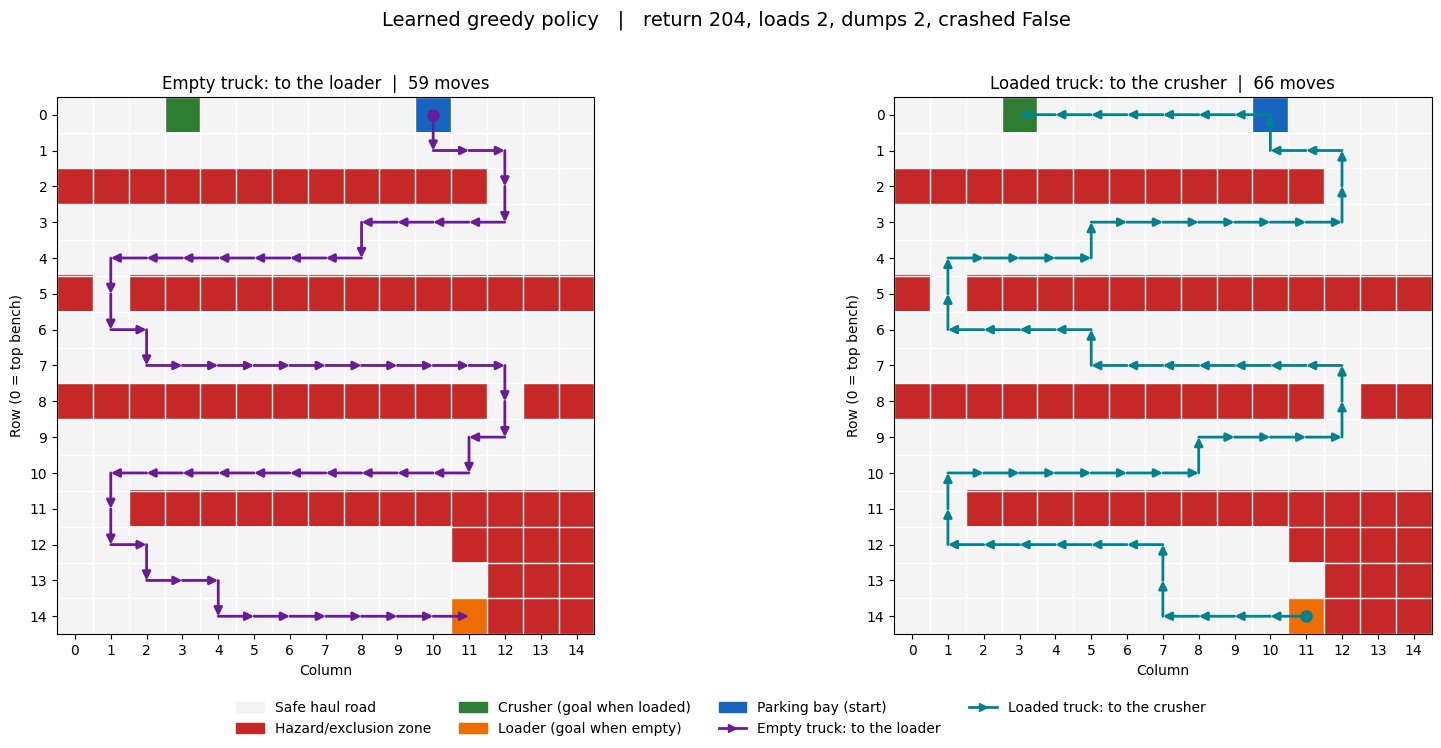

In [17]:
def greedy_rollout(Q, max_steps=MAX_STEPS):
    env = MinePitEnv(max_steps=max_steps)
    s = env.reset()
    path = [(s, None)]
    totals = {'return': 0, 'loads': 0, 'dumps': 0, 'crashed': False}
    while True:
        a = int(np.argmax(Q[s[2], s[0], s[1]]))   # pure greedy, no exploration
        s, r, terminated, truncated, event = env.step(a)
        path.append((s, a))
        totals['return'] += r
        totals['loads'] += event == 'loaded'
        totals['dumps'] += event == 'dumped'
        totals['crashed'] |= event == 'collision'
        if terminated or truncated:
            break
    return path, totals


def split_legs(path):
    """Split a greedy rollout into legs, one per stretch of constant load state.

    Returns {EMPTY: [(cells, complete), ...], LOADED: [...]} where `cells` is a
    list of (row, col) and `complete` is True when the leg ended at its goal
    (the load flag flipped). The goal cell is included as the last cell of the
    leg it finishes, and again as the first cell of the next leg.
    """
    legs = {EMPTY: [], LOADED: []}
    cells, load = [], None
    for state, _ in path:
        r, c, l = state
        if load is None:
            load, cells = l, [(r, c)]
        elif l == load:
            cells.append((r, c))
        else:                                   # flag flipped: leg reached its goal
            cells.append((r, c))
            legs[load].append((cells, True))
            load, cells = l, [(r, c)]
    if len(cells) > 1:                          # leg still under way at step limit / crash
        legs[load].append((cells, False))
    return legs


def render_policy_maps(path, totals=None):
    """Two maps of the learned greedy policy: the first complete empty leg
    (parking bay -> loader) and the first complete loaded leg (loader -> crusher)."""
    legs = split_legs(path)
    spec = [(EMPTY,  "#6a1b9a", "Empty truck: to the loader"),
            (LOADED, "#00838f", "Loaded truck: to the crusher")]

    fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
    handles = map_legend_handles()
    for ax, (load, color, label) in zip(axes, spec):
        # Prefer the first completed leg; fall back to whatever partial leg exists
        options = legs[load]
        complete = [cells for cells, done in options if done]
        cells = complete[0] if complete else (options[0][0] if options else None)
        status = "" if complete else "  (did not reach goal)"
        n_moves = len(cells) - 1 if cells else 0
        render_grid(cells, title=f"{label}  |  {n_moves} moves{status}", ax=ax,
                    route_color=color, route_label=label,
                    show_direction=True, legend=False)
        handles.append(mlines.Line2D([], [], color=color, lw=2, marker=">",
                                     markersize=6, label=label))

    # One shared legend under both maps
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
    suffix = (f"   |   return {totals['return']}, loads {totals['loads']}, "
              f"dumps {totals['dumps']}, crashed {totals['crashed']}") if totals else ""
    fig.suptitle("Learned greedy policy" + suffix, fontsize=14)
    plt.tight_layout(rect=(0, 0.07, 1, 0.96))
    plt.show()


path, totals = greedy_rollout(Q)
print(totals)
render_policy_maps(path, totals)


## 4. How Q-Learning Works — The Theory, in Plain English 🧠

Q-Learning answers one question for every state the agent could ever be in:

> *"If I take action **a** while in state **s**, and then behave optimally forever after,
> how much total (discounted) reward can I expect?"*

That expected value is called **Q(s, a)**, and we store one number for every
**(state, action)** combination in a **Q-table** — literally a big lookup table.

### The Q-table for our mine
Our Q-table has shape **`(14, 15, 5)`** — 14×15 = 210 states, each with 5 possible actions
(up/right/down/left/wait). That's **1050 numbers** the agent must learn, all starting at zero
(complete ignorance) and gradually refined through experience.

### The update rule (the heart of the algorithm)

$$
Q(s,a) \leftarrow Q(s,a) + \alpha \Big[\, \underbrace{r + \gamma \max_{a'} Q(s', a')}_{\text{"TD target": what I now believe } Q(s,a) \text{ should be}} - \underbrace{Q(s,a)}_{\text{what I currently believe}} \Big]
$$

| Symbol | Name | Intuition for a haul truck |
|---|---|---|
| $s, a$ | current state & action | "I'm at cell (3,4) and I chose to go 'right'" |
| $r$ | immediate reward | "That move cost me 1 unit of fuel/time" (or -10 if it drove into a hazard, or +10 if it reached the loading bay) |
| $s'$ | the resulting next state | "Now I'm at cell (3,5)" |
| $\gamma$ (gamma) | **discount factor** (0–1) | "How much do I care about rewards far in the future vs. right now?" High γ (e.g. 0.95) = plan far ahead, like a fleet dispatcher optimizing total shift efficiency, not just the next few meters |
| $\alpha$ (alpha) | **learning rate** (0–1) | "How much do I trust this one new experience vs. everything I've learned before?" |
| $\max_{a'} Q(s',a')$ | best possible value from the next state | "Assuming I act optimally from now on, what's the best outcome available from where I just landed?" |

### Exploration vs. exploitation — the **epsilon-greedy** policy

While training, the agent must balance two competing needs:

- **Exploitation** — use its current best-known route (efficient, but might miss a better,
  undiscovered route, or a route around a newly-changed hazard).
- **Exploration** — try random, unproven moves (risky/inefficient short-term, but necessary
  to *discover* good routes in the first place).

We use the standard **epsilon-greedy** strategy:

- With probability **ε (epsilon)** → take a **random** action (explore)
- With probability **1 − ε** → take the **currently best-known** action (exploit)

> ⚠️ **An update from an original implementation.** In the *original* version of this
> notebook performed in 2021, epsilon was defined "backwards" (a *low* epsilon of 0.1 meant the agent
> exploited 10% of the time and explored 90% of the time — the opposite of the textbook
> convention).
> In this updated version, this is corrected below **by** an upgrade to a **decaying epsilon schedule**:
> the agent explores heavily at first (when it knows nothing) and gradually shifts to
> exploitation as it gains experience — mirroring how a real autonomous-vehicle rollout
> program runs many supervised "shadow-mode" trial trips before trusting the automated
> route planner in production.


## 5. Implementation — Core Functions, Explained 🔧

The environment itself (`MinePitEnv`, Section 3) already knows the **rules of the mine**: where the hazards are, what each move costs, and when the load flag flips. This section adds the functions the **agent** needs on top of it. Each one is documented with **what it does**, **why it exists**, and **how it maps to a real autonomous-vehicle software stack**.


| Function | What it does |
|---|---|
| `place_truck` | Puts the truck on any cell, with either load state (exploring starts and robustness tests) |
| `choose_action` | Epsilon-greedy choice among the **5 actions**, using the Q-values for the truck's current load state |
| `epsilon_by_episode` | The decaying exploration schedule |
| `q_update` | The Q-learning update rule (the heart of the algorithm) |
| `bfs_shortest_path` | Ground-truth shortest safe route between two cells, used later as a benchmark |


Two things are different from a plain grid-world:

- **The state is `(row, col, load)`**, so the Q-table has shape `(2, ENV_ROWS, ENV_COLS, N_ACTIONS)`. The first index is the load state, and the same cell has a different row of Q-values for an empty truck and a loaded one.
- **There are 5 actions** (up, right, down, left and **wait**). Waiting is a real choice with a real cost (the delay penalty), so the agent can learn that it is never worth doing.

In [19]:
def place_truck(env, cell, load=EMPTY):
    '''Put the truck on `cell` with the given load state and return the new state.

    Used for "exploring starts" in training and for robustness tests. In normal
    operation the truck always starts empty in the parking bay (env.reset()).

    Real-world analogue: re-initialising a vehicle's localisation after a stall,
    a detour, or a shift-change relocation.
    '''
    env.row, env.col = cell
    env.load = load
    env.prev = None          # no "previous cell", so the first move cannot be a backtrack
    return env.state


def choose_action(state, epsilon, q_table, rng):
    '''Epsilon-greedy action selection over all 5 actions:

        with probability epsilon       -> explore  (random action)
        with probability (1 - epsilon) -> exploit  (best-known action)

    `state` is (row, col, load), so the Q-values come from the right load layer.
    Ties are broken at random: at the start every Q-value is 0, and always
    picking the first action would make the truck drive in a straight line.

    Real-world analogue: the decision layer that chooses between "run the
    proven route" and "try the newly suggested detour" during controlled testing.
    '''
    row, col, load = state
    if rng.random() < epsilon:
        return rng.randrange(N_ACTIONS)                       # EXPLORE
    q_values = q_table[load, row, col]
    best = np.flatnonzero(q_values == q_values.max())
    return int(rng.choice(best))                              # EXPLOIT (random tie-break)


def epsilon_by_episode(episode, epsilon_start, epsilon_end, decay_episodes):
    '''Linearly decay epsilon from `epsilon_start` to `epsilon_end` over
    `decay_episodes` episodes, then hold it at `epsilon_end`.

    Real-world analogue: a phased autonomy rollout. Lots of exploratory,
    supervised test runs early on, tapering to mostly autonomous operation
    (with a small margin of randomised checks) once the system is mature.
    '''
    if decay_episodes <= 0:
        return epsilon_end
    fraction = min(1.0, episode / decay_episodes)
    return epsilon_start + fraction * (epsilon_end - epsilon_start)


def q_update(q_table, state, action, reward, next_state, terminated, alpha, gamma):
    '''One Q-learning update:

        Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]

    If the episode just ended in a collision (`terminated`), nothing follows the
    crash, so the target is the reward alone. Hitting the step limit is NOT a
    failure of the truck, so the update still looks ahead (it "bootstraps").

    Note that reaching a goal is not terminal: the load flag flips and the truck
    carries on, so the next state's value is the value of the *other* leg.

    Returns the TD error (how surprised the agent was by this step).
    '''
    row, col, load = state
    next_row, next_col, next_load = next_state
    old_q = q_table[load, row, col, action]
    if terminated:
        td_target = reward
    else:
        td_target = reward + gamma * np.max(q_table[next_load, next_row, next_col])
    td_error = td_target - old_q
    q_table[load, row, col, action] = old_q + alpha * td_error
    return td_error


def bfs_shortest_path(start, goal):
    '''Breadth-first search over the SAME grid, ignoring rewards entirely.
    This gives the objective, ground-truth shortest safe route between two
    cells, independent of anything the Q-learning agent has (or hasn't)
    learned. We use it as the benchmark for route efficiency in Section 9.
    '''
    visited = {start}
    queue = deque([[start]])
    while queue:
        current_path = queue.popleft()
        r, c = current_path[-1]
        for dr, dc in [(-1, 0), (0, 1), (1, 0), (0, -1)]:
            nr, nc = r + dr, c + dc
            in_bounds = 0 <= nr < ENV_ROWS and 0 <= nc < ENV_COLS
            if in_bounds and (nr, nc) not in HAZARD_CELLS and (nr, nc) not in visited:
                new_path = current_path + [(nr, nc)]
                if (nr, nc) == goal:
                    return new_path
                visited.add((nr, nc))
                queue.append(new_path)
    return None

### ✅ Sanity-check the environment mechanics

Good engineering practice: **unit-test your environment before you ever train an agent on top of it.**

A bug in `MinePitEnv.step`:
> - a flipped row/column, a missing boundary check,
> - a reward paid at the wrong moment,
> - or a load flag that never flips,

will silently produce a "trained" agent that looks plausible but is actually learning a broken mine map.

The checks below place the truck by hand, take **one** action, and compare the outcome with the rule table. The cells they use are found from the map, so the tests keep working if you edit `hazard_zones`.

| Check | Expected result |
|---|---|
| Action set | 5 actions: up, right, down, left and **wait**. Q-table shape is `2 load states, rows, cols, 5` |
| Ordinary move | step cost `-1`, truck moves one cell in the right direction |
| Hazard cell or leaving the grid | `-100` and the episode ends (off-grid is treated as a wall) |
| Wait, backtrack (A→B→A) | delay penalty `-10` |
| Correct goal | `+100` (`+50` cycle bonus at the crusher) and the load flag flips |
| Wrong goal | `-10`, load flag unchanged |
| Step limit | episode is *truncated*, not terminated |
| Solvable map | a breadth-first search can reach the loader and the crusher |

In [20]:
# ── Sanity checks for the haul-truck environment (MinePitEnv) ────────────────
# Each check builds a fresh environment, places the truck by hand, takes ONE
# action and compares the result with the rule table. The cells used are found
# from the map, so the tests still work if you edit hazard_zones.

def make_env(cell, load=EMPTY, prev=None, max_steps=MAX_STEPS):
    """A fresh environment with the truck placed on `cell`."""
    env = MinePitEnv(max_steps=max_steps)
    env.row, env.col = cell
    env.load, env.prev = load, prev
    return env


def is_free(cell):
    r, c = cell
    return 0 <= r < ENV_ROWS and 0 <= c < ENV_COLS and cell not in HAZARD_CELLS


def neighbour(cell, action):
    dr, dc = ACTION_DELTAS[action]
    return (cell[0] + dr, cell[1] + dc)


def is_plain(cell):
    """Free cell that is not a goal (so a move onto it is an ordinary move)."""
    return is_free(cell) and cell not in (CRUSHER_STATE, LOAD_STATE)


def check(name, condition):
    assert condition, f"FAILED: {name}"
    print(f"  ✅ {name}")


print("1. Action set")
check("5 actions: up, right, down, left, wait", ACTIONS == ['up', 'right', 'down', 'left', 'wait'])
check("N_ACTIONS == 5 and WAIT == 4", N_ACTIONS == 5 and WAIT == 4)
check("ACTION_DELTAS has one entry per action", len(ACTION_DELTAS) == N_ACTIONS)
check("up lowers the row, down raises it", ACTION_DELTAS[UP] == (-1, 0) and ACTION_DELTAS[DOWN] == (1, 0))
check("right raises the column, left lowers it", ACTION_DELTAS[RIGHT] == (0, 1) and ACTION_DELTAS[LEFT] == (0, -1))
check("wait does not move the truck", ACTION_DELTAS[WAIT] == (0, 0))
check("Q-table shape is (load, row, col, action)", Q.shape == (2, ENV_ROWS, ENV_COLS, N_ACTIONS))
print(f"     Q-table entries: 2 x {ENV_ROWS} x {ENV_COLS} x {N_ACTIONS} = {Q.size:,}")

print("2. Reset")
env = MinePitEnv()
check("reset() puts the truck at the parking bay, empty", env.reset() == (*START_STATE, EMPTY))
check("start, crusher and loader are not hazard cells",
      not ({START_STATE, CRUSHER_STATE, LOAD_STATE} & HAZARD_CELLS))

print("3. Ordinary moves cost STEP_COST and go the right way")
# Find a plain cell whose four neighbours are all plain, so every direction is a normal move
cell = next(c for c in sorted(FREE_CELLS)
            if is_plain(c) and all(is_plain(neighbour(c, a)) for a in (UP, RIGHT, DOWN, LEFT)))
for a in (UP, RIGHT, DOWN, LEFT):
    env = make_env(cell)
    state, reward, terminated, truncated, event = env.step(a)
    check(f"{ACTIONS[a]:>5} from {cell} -> {neighbour(cell, a)}, reward {STEP_COST}",
          state[:2] == neighbour(cell, a) and reward == STEP_COST
          and not terminated and not truncated and event == 'move')

print("4. Collisions end the episode with COLLISION_PENALTY")
# Hazard cells
hazard_hits = [(c, a) for c in FREE_CELLS for a in (UP, RIGHT, DOWN, LEFT)
               if neighbour(c, a) in HAZARD_CELLS]
cell, a = hazard_hits[0]
state, reward, terminated, _, event = make_env(cell).step(a)
check(f"driving {ACTIONS[a]} from {cell} into hazard {neighbour(cell, a)}",
      reward == COLLISION_PENALTY and terminated and event == 'collision')
# Grid edges: off-grid counts as a wall (the truck no longer 'stays put')
for edge_name, action, on_edge in [
        ("top edge",    UP,    lambda c: c[0] == 0),
        ("bottom edge", DOWN,  lambda c: c[0] == ENV_ROWS - 1),
        ("left edge",   LEFT,  lambda c: c[1] == 0),
        ("right edge",  RIGHT, lambda c: c[1] == ENV_COLS - 1)]:
    cell = next(c for c in FREE_CELLS if on_edge(c))
    state, reward, terminated, _, event = make_env(cell).step(action)
    check(f"leaving the {edge_name} from {cell}",
          reward == COLLISION_PENALTY and terminated and event == 'collision')

print("5. Delays cost DELAY_PENALTY")
for label, cell in [("in the parking bay", START_STATE), ("on the haul road", FREE_CELLS[len(FREE_CELLS) // 2])]:
    state, reward, terminated, _, event = make_env(cell).step(WAIT)
    check(f"waiting {label} {cell}: stays put, reward {DELAY_PENALTY}",
          state[:2] == cell and reward == DELAY_PENALTY and not terminated and event == 'wait')
cell = next(c for c in sorted(FREE_CELLS) if is_plain(c) and is_plain(neighbour(c, RIGHT)))
env = make_env(cell)
env.step(RIGHT)
state, reward, _, _, event = env.step(LEFT)
check("A -> B -> A is a backtrack (second move)", reward == DELAY_PENALTY and event == 'backtrack')

print("6. Goals, load flag and cycle bonus")
OPPOSITE = {UP: DOWN, DOWN: UP, LEFT: RIGHT, RIGHT: LEFT}

def approach(goal):
    """A plain cell next to `goal`, and the action that steps from it onto the goal."""
    for a in (UP, RIGHT, DOWN, LEFT):
        cell = neighbour(goal, OPPOSITE[a])
        if is_plain(cell):
            return cell, a

loader_nb,  to_loader_action  = approach(LOAD_STATE)
crusher_nb, to_crusher_action = approach(CRUSHER_STATE)

state, reward, terminated, _, event = make_env(loader_nb, EMPTY).step(to_loader_action)
check(f"empty truck reaches the loader: +{GOAL_REWARD}, flag -> loaded",
      state == (*LOAD_STATE, LOADED) and reward == GOAL_REWARD and not terminated and event == 'loaded')
state, reward, terminated, _, event = make_env(crusher_nb, LOADED).step(to_crusher_action)
check(f"loaded truck reaches the crusher: +{GOAL_REWARD + CYCLE_BONUS} (incl. cycle bonus), flag -> empty",
      state == (*CRUSHER_STATE, EMPTY) and reward == GOAL_REWARD + CYCLE_BONUS and not terminated and event == 'dumped')
state, reward, _, _, event = make_env(crusher_nb, EMPTY).step(to_crusher_action)
check(f"empty truck at the crusher is the wrong goal: {DELAY_PENALTY}, flag unchanged",
      reward == DELAY_PENALTY and state[2] == EMPTY and event == 'wrong_goal')
state, reward, _, _, event = make_env(loader_nb, LOADED).step(to_loader_action)
check(f"loaded truck at the loader is the wrong goal: {DELAY_PENALTY}, flag unchanged",
      reward == DELAY_PENALTY and state[2] == LOADED and event == 'wrong_goal')
env = make_env(loader_nb, EMPTY)
env.step(to_loader_action)                              # load up
state, reward, _, _, event = env.step(OPPOSITE[to_loader_action])   # reverse out the way we came
check(f"turning round at a goal is free (ordinary {STEP_COST}, not a backtrack)",
      reward == STEP_COST and event == 'move')

print("7. Episode limits")
env = make_env(START_STATE, max_steps=3)
outcomes = [env.step(WAIT) for _ in range(3)]
check("episode is truncated (not terminated) at the step limit",
      [o[3] for o in outcomes] == [False, False, True] and not any(o[2] for o in outcomes))
cell, a = hazard_hits[0]
env = make_env(cell, max_steps=1)
_, _, terminated, truncated, _ = env.step(a)
check("a collision on the last step is terminal, not truncated", terminated and not truncated)

print("8. The map can be solved")
def shortest(start, goal):
    """Fewest moves between two cells over safe cells (BFS, 4 directions, no rewards)."""
    seen, queue = {start}, deque([(start, 0)])
    while queue:
        cell, d = queue.popleft()
        if cell == goal:
            return d
        for a in (UP, RIGHT, DOWN, LEFT):
            nxt = neighbour(cell, a)
            if is_free(nxt) and nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, d + 1))
    return None

to_loader  = shortest(START_STATE, LOAD_STATE)
to_crusher = shortest(LOAD_STATE, CRUSHER_STATE)
check("loader is reachable from the parking bay", to_loader is not None)
check("crusher is reachable from the loader", to_crusher is not None)
print(f"     shortest bay -> loader: {to_loader} moves   loader -> crusher: {to_crusher} moves")
steps_to_first_dump = to_loader + to_crusher
cycle_steps = 2 * to_crusher                            # crusher -> loader -> crusher
best_dumps, t = 0, steps_to_first_dump
while t <= MAX_STEPS:
    best_dumps += 1
    t += cycle_steps
print(f"     best case inside MAX_STEPS = {MAX_STEPS}: first dump at step {steps_to_first_dump}, "
      f"then one more every {cycle_steps} steps -> {best_dumps} dump(s)")

print("\n✅ All environment sanity checks passed: 5 actions, rules and map behave as specified.")

1. Action set
  ✅ 5 actions: up, right, down, left, wait
  ✅ N_ACTIONS == 5 and WAIT == 4
  ✅ ACTION_DELTAS has one entry per action
  ✅ up lowers the row, down raises it
  ✅ right raises the column, left lowers it
  ✅ wait does not move the truck
  ✅ Q-table shape is (load, row, col, action)
     Q-table entries: 2 x 15 x 15 x 5 = 2,250
2. Reset
  ✅ reset() puts the truck at the parking bay, empty
  ✅ start, crusher and loader are not hazard cells
3. Ordinary moves cost STEP_COST and go the right way
  ✅    up from (1, 12) -> (0, 12), reward -1
  ✅ right from (1, 12) -> (1, 13), reward -1
  ✅  down from (1, 12) -> (2, 12), reward -1
  ✅  left from (1, 12) -> (1, 11), reward -1
4. Collisions end the episode with COLLISION_PENALTY
  ✅ driving down from (1, 0) into hazard (2, 0)
  ✅ leaving the top edge from (0, 0)
  ✅ leaving the bottom edge from (14, 0)
  ✅ leaving the left edge from (0, 0)
  ✅ leaving the right edge from (0, 14)
5. Delays cost DELAY_PENALTY
  ✅ waiting in the parking 

## 6. The Training Loop 🎯

This is where Q-Learning actually happens. We wrap the whole training procedure in a single `train_agent(...)` function with **named, tunable hyperparameters**. This is the function the interactive sliders in Section 7 call directly.

Each step of an episode does the same thing:

1. **Choose** an action (`choose_action`, epsilon-greedy over the 5 actions).
2. **Act**: `env.step(action)` returns the next state, the reward, and whether the episode ended.
3. **Learn**: `q_update` nudges `Q[load, row, col, action]` toward the reward plus the discounted best value of the next state.

An episode ends when the truck **collides** (terminal) or reaches the **step limit** (`MAX_STEPS`, truncated). Reaching a goal does **not** end it: the load flag flips and the truck carries on, which is what turns two goals into a continuous haul loop.

### Hyperparameters that matter for this mine
- **Discount factor γ = 0.995.** The shortest routes are about 60 moves each way. With γ = 0.95 the loader's +100 is worth `100 × 0.95^59 ≈ 5` from the parking bay, which is smaller than the cost of the steps it takes to get there, so the truck never learns to go. A discount close to 1 is needed for long haul roads.
- **Episodes = 30,000, ε decaying over 20,000.** The loaded half of the Q-table only starts to learn once the truck has reached the loader and then the crusher at least once, so the agent needs plenty of early exploration.

### Design upgrade: "exploring starts"
If every episode begins in the parking bay, the agent only gets dense experience *along the route it currently believes is best*. Cells far from that route are rarely visited, and their Q-values stay at zero.

With **exploring starts**, each training episode begins from a **random safe cell with a random load state**. In a mining context this is like training the route planner from historical GPS traces of many vehicles, start points and shifts, so the agent copes if a truck stalls and restarts somewhere unexpected, loaded or empty.

In [21]:
def train_agent(
    episodes=30_000,
    epsilon_start=1.0,
    epsilon_end=0.05,
    decay_episodes=20_000,
    discount_factor=0.995,
    learning_rate=0.1,
    max_steps_per_episode=MAX_STEPS,
    exploring_starts=True,
    seed=SEED,
):
    '''Train a tabular Q-Learning agent on the haul-truck environment.

    Parameters
    ----------
    episodes : int
        Number of training episodes. Each one ends on a collision or at the step limit.
    epsilon_start, epsilon_end, decay_episodes : float, float, int
        Define the linear epsilon-decay exploration schedule.
    discount_factor (gamma) : float in [0, 1]
        How much future reward matters relative to immediate reward.
    learning_rate (alpha) : float in (0, 1]
        How aggressively each new experience updates the Q-table.
    max_steps_per_episode : int
        Step limit that truncates an episode (300 means roughly two full hauls).
    exploring_starts : bool
        True: each episode starts on a random safe cell with a random load state.
        False: every episode starts empty in the parking bay.
    seed : int
        Random seed for full reproducibility.

    Returns
    -------
    q_table : np.ndarray, shape (2, ENV_ROWS, ENV_COLS, N_ACTIONS)
        The learned action-value table, indexed [load, row, col, action].
    history : dict of lists
        Per-episode diagnostics: 'reward', 'steps', 'collided', 'loads',
        'dumps', 'epsilon'. Used for learning curves and validation.
    '''
    rng = random.Random(seed)
    q_table = np.zeros((2, ENV_ROWS, ENV_COLS, N_ACTIONS))
    env = MinePitEnv(max_steps=max_steps_per_episode)

    history = {"reward": [], "steps": [], "collided": [],
               "loads": [], "dumps": [], "epsilon": []}

    for episode in range(episodes):
        epsilon = epsilon_by_episode(episode, epsilon_start, epsilon_end, decay_episodes)

        state = env.reset()                       # parking bay, empty
        if exploring_starts:
            state = place_truck(env, rng.choice(FREE_CELLS), load=rng.randrange(2))

        total_reward, loads, dumps, collided = 0.0, 0, 0, False

        while True:
            action = choose_action(state, epsilon, q_table, rng)
            next_state, reward, terminated, truncated, event = env.step(action)

            q_update(q_table, state, action, reward, next_state, terminated,
                     learning_rate, discount_factor)

            total_reward += reward
            loads   += event == 'loaded'
            dumps   += event == 'dumped'
            collided = collided or event == 'collision'
            state = next_state

            if terminated or truncated:
                break

        history["reward"].append(total_reward)
        history["steps"].append(env.steps)
        history["collided"].append(collided)
        history["loads"].append(loads)
        history["dumps"].append(dumps)
        history["epsilon"].append(epsilon)

    return q_table, history


print("✅ train_agent() defined. Ready to train — see the interactive lab below.")

✅ train_agent() defined. Ready to train — see the interactive lab below.



## 7. 🎛️ Interactive Lab — Train the Agent Yourself

Use the sliders below to set the **hyperparameters** and click **"Run Interact"**. The
agent will train from scratch with your chosen settings and immediately show:

- 📈 the learning curve (steps-to-goal per episode)
- 🗺️ the final learned route from the depot to the loading bay
- 📊 a live scorecard of how well the agent learned

### 🧪 Suggested experiments
| Try this | What you should observe |
|---|---|
| Set `episodes` very low (e.g. 200) | The agent likely fails to reach the goal reliably — not enough experience yet |
| Set `epsilon_end` close to `epsilon_start` (little decay) | Noisier, less stable learning curve — the agent never settles into exploiting what it has learned |
| Set `discount_factor` very low (e.g. 0.3) | The agent becomes "short-sighted" — it may take a longer route because it undervalues the distant goal reward |
| Set `learning_rate` very high (e.g. 0.9) | Learning becomes unstable / jumpy — each new experience overwrites almost all prior learning |
| Turn OFF `exploring_starts` | Training is slower to generalize; the agent may still solve the fixed depot route, but performs worse from unfamiliar starting cells |

> 🎓 This is the single most valuable section of the notebook for building *intuition* —
> reinforcement learning hyperparameters have real, visible, sometimes counter-intuitive
> effects, and there's no substitute for direct experimentation.


In [ ]:

def run_training_experiment(
    episodes=10_000,
    epsilon_start=1.0,
    epsilon_end=0.05,
    decay_episodes=6_000,
    discount_factor=0.95,
    learning_rate=0.10,
    exploring_starts=True,
):
    '''Interactive wrapper: trains the agent with the chosen hyperparameters
    and renders a full diagnostic dashboard (learning curve + learned route
    + scorecard). This is the function wired up to the ipywidgets sliders.
    '''
    q_table, history = train_agent(
        episodes=episodes,
        epsilon_start=epsilon_start,
        epsilon_end=epsilon_end,
        decay_episodes=decay_episodes,
        discount_factor=discount_factor,
        learning_rate=learning_rate,
        exploring_starts=exploring_starts,
        seed=SEED,
    )

    path = greedy_path(q_table, START_STATE)
    reached_goal = path[-1] == GOAL_STATE

    # ---- Dashboard layout: learning curve (left) + route map (right) ----
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    window = max(1, episodes // 100)
    smoothed = pd.Series(history["steps"]).rolling(window, min_periods=1).mean()
    axes[0].plot(history["steps"], color="lightgray", linewidth=0.6, label="Raw steps/episode")
    axes[0].plot(smoothed, color="#1565c0", linewidth=2.2, label=f"Rolling mean (window={window})")
    axes[0].set_xlabel("Training episode")
    axes[0].set_ylabel("Steps taken to reach a terminal state")
    axes[0].set_title("Learning Curve: Efficiency Over Time")
    axes[0].legend()

    render_grid(highlight_path=path,
                title=f"Learned Route from Depot  |  Reached goal: {'✅' if reached_goal else '❌'}",
                ax=axes[1])

    plt.tight_layout()
    plt.show()

    # ---- Scorecard ----
    first_n = max(10, episodes // 20)
    hazard_rate_early = np.mean(history["hit_hazard"][:first_n])
    hazard_rate_late  = np.mean(history["hit_hazard"][-first_n:])
    steps_early = np.mean(history["steps"][:first_n])
    steps_late  = np.mean(history["steps"][-first_n:])

    print("─" * 60)
    print(" TRAINING SCORECARD")
    print("─" * 60)
    print(f" Episodes trained:                 {episodes:,}")
    print(f" Final route length (from depot):  {len(path)-1} steps")
    print(f" Reached loading bay?              {'YES ✅' if reached_goal else 'NO ❌ — try more episodes'}")
    print(f" Hazard-contact rate  (first {first_n:>4}):  {hazard_rate_early:6.1%}")
    print(f" Hazard-contact rate  (last  {first_n:>4}):  {hazard_rate_late:6.1%}")
    print(f" Avg steps/episode    (first {first_n:>4}):  {steps_early:6.1f}")
    print(f" Avg steps/episode    (last  {first_n:>4}):  {steps_late:6.1f}")
    print("─" * 60)

    return q_table, history, path


# ── Build the interactive control panel ──────────────────────────────────────
interact_manual(
    run_training_experiment,
    episodes=IntSlider(min=200, max=20000, step=200, value=10000,
                        description="Episodes", continuous_update=False),
    epsilon_start=FloatSlider(min=0.1, max=1.0, step=0.05, value=1.0,
                               description="ε start", continuous_update=False),
    epsilon_end=FloatSlider(min=0.0, max=0.5, step=0.01, value=0.05,
                             description="ε end", continuous_update=False),
    decay_episodes=IntSlider(min=100, max=20000, step=100, value=6000,
                              description="ε decay episodes", continuous_update=False),
    discount_factor=FloatSlider(min=0.1, max=0.999, step=0.01, value=0.95,
                                 description="γ (gamma)", continuous_update=False),
    learning_rate=FloatSlider(min=0.01, max=0.9, step=0.01, value=0.10,
                               description="α (alpha)", continuous_update=False),
    exploring_starts=Dropdown(options=[("Yes — random safe start each episode", True),
                                        ("No — always start at depot", False)],
                               value=True, description="Exploring starts"),
)


interactive(children=(IntSlider(value=10000, continuous_update=False, description='Episodes', max=20000, min=2…

<function __main__.run_training_experiment(episodes=10000, epsilon_start=1.0, epsilon_end=0.05, decay_episodes=6000, discount_factor=0.95, learning_rate=0.1, exploring_starts=True)>


## 8. Reference Training Run (Default Hyperparameters)

The interactive lab above is great for exploration, but notebooks should also always contain
a **deterministic, non-interactive reference run** — this is what you'd rerun in a CI/CD
pipeline every time the environment or algorithm code changes, to catch regressions.

We use the hyperparameters recommended by the theory in Section 4:


In [ ]:

# ── Deterministic reference run — this is our "golden" baseline ─────────────
q_table, history = train_agent(
    episodes=10_000,
    epsilon_start=1.0,
    epsilon_end=0.05,
    decay_episodes=6_000,
    discount_factor=0.95,
    learning_rate=0.1,
    exploring_starts=True,
    seed=SEED,
)

print("✅ Training complete.")
print(f"Trained on {len(history['steps']):,} episodes.")


✅ Training complete.
Trained on 10,000 episodes.



### 📈 Learning curve — did the agent actually get better?


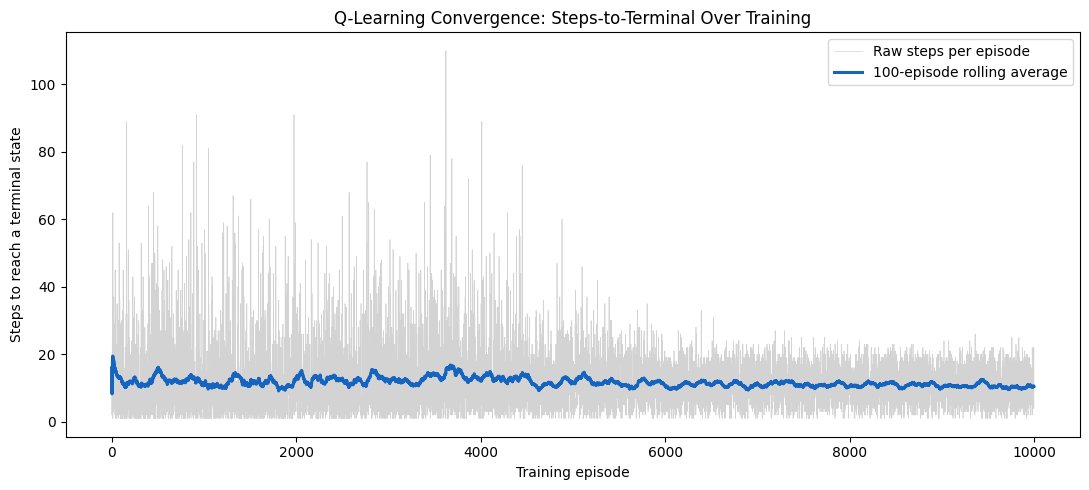

Interpretation: a downward, flattening curve means the agent is finding shorter, safer routes and its policy is stabilizing (converging).


In [ ]:

fig, ax = plt.subplots(figsize=(11, 5))
window = 100
smoothed_steps = pd.Series(history["steps"]).rolling(window, min_periods=1).mean()

ax.plot(history["steps"], color="lightgray", linewidth=0.5, label="Raw steps per episode")
ax.plot(smoothed_steps, color="#1565c0", linewidth=2.2, label=f"{window}-episode rolling average")
ax.set_xlabel("Training episode")
ax.set_ylabel("Steps to reach a terminal state")
ax.set_title("Q-Learning Convergence: Steps-to-Terminal Over Training")
ax.legend()
plt.tight_layout()
plt.show()

print("Interpretation: a downward, flattening curve means the agent is finding "
      "shorter, safer routes and its policy is stabilizing (converging).")



### 🗺️ The learned route

Now we roll out the **greedy** (pure-exploitation) policy from the depot and see the exact
sequence of grid cells the trained agent chooses to drive through.


Learned route (row, col) sequence:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (5, 1), (6, 1), (7, 1), (8, 1), (9, 1), (9, 0), (10, 0), (11, 0), (11, 1), (11, 2), (11, 3), (11, 4), (11, 5)]

Total steps: 18
Reached the loading bay: ✅ YES


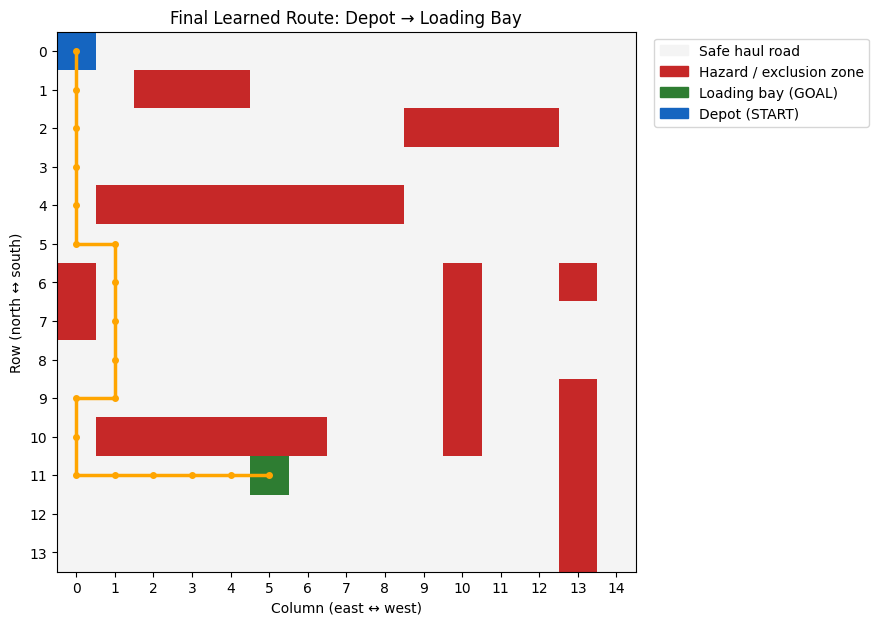

In [ ]:

learned_path = greedy_path(q_table, START_STATE)
print("Learned route (row, col) sequence:")
print(learned_path)
print(f"\nTotal steps: {len(learned_path) - 1}")
print(f"Reached the loading bay: {'✅ YES' if learned_path[-1] == GOAL_STATE else '❌ NO'}")

render_grid(highlight_path=learned_path,
            title="Final Learned Route: Depot → Loading Bay")



### 🧭 The learned policy, visualized as arrows

A single route only shows what the agent does *from one starting point*. To really audit the
agent's understanding of the *entire* mine floor, we plot an arrow in **every safe cell**
pointing toward that cell's highest-value ("greedy") action. This is the single most useful
diagnostic plot for a mining-automation engineer reviewing a trained navigation policy —
you can visually spot "dead zones" (cells the agent never learned a sensible policy for)
at a glance.


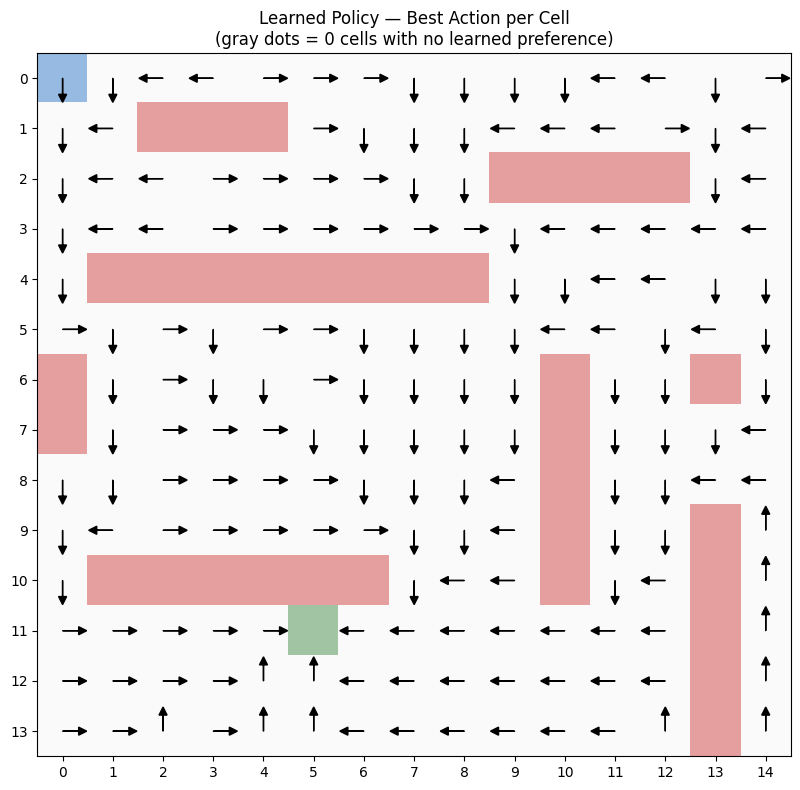


0 out of 175 safe cells still have no learned policy (0.0% coverage gap).


In [ ]:

def render_policy_arrows(q_table, title="Learned Policy — Best Action per Cell"):
    '''Draw one arrow per safe (non-terminal) cell pointing in the direction
    of the currently highest-value action. Cells where the agent never learned
    anything (Q-values all still zero) are marked with a gray dot instead of
    an arrow -- these represent gaps in training coverage.
    '''
    # (delta_row, delta_col) for each action index, matching ACTIONS order
    action_deltas = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}  # up, right, down, left

    grid = np.zeros((ENV_ROWS, ENV_COLS))
    for (r, c) in HAZARD_CELLS:
        grid[r, c] = 1
    grid[GOAL_STATE] = 2
    grid[START_STATE] = 3
    cmap = ListedColormap(["#f4f4f4", "#c62828", "#2e7d32", "#1565c0"])

    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=3, alpha=0.45)

    untrained_cells = 0
    for r in range(ENV_ROWS):
        for c in range(ENV_COLS):
            if (r, c) in HAZARD_CELLS or (r, c) == GOAL_STATE:
                continue
            if np.all(q_table[r, c] == 0):
                ax.plot(c, r, marker="o", color="gray", markersize=3)
                untrained_cells += 1
                continue
            best_action = int(np.argmax(q_table[r, c]))
            dr, dc = action_deltas[best_action]
            ax.arrow(c, r, dc * 0.32, dr * 0.32, head_width=0.16,
                      head_length=0.16, fc="black", ec="black")

    ax.set_title(f"{title}\n(gray dots = {untrained_cells} cells with no learned preference)")
    ax.set_xticks(range(ENV_COLS))
    ax.set_yticks(range(ENV_ROWS))
    plt.tight_layout()
    plt.show()
    return untrained_cells

untrained = render_policy_arrows(q_table)
print(f"\n{untrained} out of {len(FREE_CELLS)} safe cells still have no learned policy "
      f"({untrained/len(FREE_CELLS):.1%} coverage gap).")



## 9. Validating the Agent — Is It Actually Good Enough to Deploy? 📊

A learning curve that trends downward is encouraging, but it is **not sufficient evidence**
that an autonomous navigation policy is safe or efficient enough for real deployment. Below
we compute a **validation scorecard** using metrics that map directly onto criteria a mining
operations / safety team would ask about *before* signing off on any automation rollout.

| Metric | What it tells you | Why it matters for mining |
|---|---|---|
| **Success rate** | % of test rollouts that reach the loading bay without hitting a hazard | Direct proxy for operational reliability |
| **Path optimality ratio** | learned route length ÷ true shortest possible route length | Measures fuel/time efficiency vs. the theoretical best case |
| **Robustness (multi-start success rate)** | Success rate when starting from many *different* random safe cells, not just the depot | Simulates recovery from a stall, detour, or shift-change relocation |
| **Hazard-contact rate (early vs. late training)** | How often training episodes ended by hitting a hazard, early vs. late | A proxy for how quickly the agent learns to respect safety-critical zones |
| **Q-table coverage** | % of safe cells with a non-trivial (non-zero) learned policy | Flags "blind spots" the agent has never encountered |


In [ ]:

def bfs_shortest_path(start, goal):
    '''Breadth-first search over the SAME grid, ignoring rewards entirely --
    this gives us the objective, ground-truth shortest safe path length,
    independent of anything the Q-learning agent has (or hasn't) learned.
    We use this as our benchmark / upper bound on achievable efficiency.
    '''
    visited = {start}
    queue = deque([[start]])
    while queue:
        current_path = queue.popleft()
        r, c = current_path[-1]
        for dr, dc in [(-1, 0), (0, 1), (1, 0), (0, -1)]:
            nr, nc = r + dr, c + dc
            in_bounds = 0 <= nr < ENV_ROWS and 0 <= nc < ENV_COLS
            if in_bounds and (nr, nc) not in HAZARD_CELLS and (nr, nc) not in visited:
                new_path = current_path + [(nr, nc)]
                if (nr, nc) == goal:
                    return new_path
                visited.add((nr, nc))
                queue.append(new_path)
    return None


def evaluate_agent(q_table, n_robustness_samples=30, seed=0):
    '''Compute the full validation scorecard described above.'''
    rng = random.Random(seed)

    # -- 1. Optimality ratio from the depot --
    agent_path = greedy_path(q_table, START_STATE)
    agent_success = agent_path[-1] == GOAL_STATE
    optimal_path = bfs_shortest_path(START_STATE, GOAL_STATE)
    optimal_len = len(optimal_path) - 1
    agent_len = len(agent_path) - 1
    optimality_ratio = (optimal_len / agent_len) if (agent_success and agent_len > 0) else 0.0

    # -- 2. Robustness across many random safe starting cells --
    sample_starts = rng.sample(FREE_CELLS, min(n_robustness_samples, len(FREE_CELLS)))
    robustness_successes = sum(
        1 for s in sample_starts if greedy_path(q_table, s)[-1] == GOAL_STATE
    )
    robustness_rate = robustness_successes / len(sample_starts)

    # -- 3. Q-table coverage --
    trained_cells = sum(
        1 for (r, c) in FREE_CELLS if not np.all(q_table[r, c] == 0)
    )
    coverage = trained_cells / len(FREE_CELLS)

    return pd.DataFrame([
        {"Metric": "Depot → goal: reached?",       "Value": "YES" if agent_success else "NO",
         "Target": "YES",              "Pass": agent_success},
        {"Metric": "Depot → goal: route length",    "Value": agent_len,
         "Target": f"<= {int(optimal_len * 1.25)} (optimal={optimal_len})",
         "Pass": agent_len <= optimal_len * 1.25},
        {"Metric": "Path optimality ratio",          "Value": round(optimality_ratio, 3),
         "Target": ">= 0.80",           "Pass": optimality_ratio >= 0.80},
        {"Metric": f"Robustness ({len(sample_starts)} random starts)",
         "Value": f"{robustness_successes}/{len(sample_starts)} ({robustness_rate:.1%})",
         "Target": ">= 90%",           "Pass": robustness_rate >= 0.90},
        {"Metric": "Q-table coverage (safe cells trained)",
         "Value": f"{trained_cells}/{len(FREE_CELLS)} ({coverage:.1%})",
         "Target": ">= 85%",           "Pass": coverage >= 0.85},
    ])


scorecard = evaluate_agent(q_table)
scorecard


,Metric,Value,Target,Pass
0,Depot → goal: reached?,YES,YES,True
1,Depot → goal: route length,18,<= 22 (optimal=18),True
2,Path optimality ratio,1.0,>= 0.80,True
3,Robustness (30 random starts),30/30 (100.0%),>= 90%,True
4,Q-table coverage (safe cells trained),175/175 (100.0%),>= 85%,True


In [ ]:

# ── Human-readable pass/fail summary ─────────────────────────────────────────
all_pass = scorecard["Pass"].all()
print("=" * 62)
print(f" OVERALL VALIDATION RESULT: {'✅ READY FOR PILOT TESTING' if all_pass else '⚠️ NEEDS MORE TRAINING / TUNING'}")
print("=" * 62)
for _, row in scorecard.iterrows():
    flag = "✅" if row["Pass"] else "❌"
    print(f" {flag}  {row['Metric']:<45} -> {row['Value']}")


 OVERALL VALIDATION RESULT: ✅ READY FOR PILOT TESTING
 ✅  Depot → goal: reached?                        -> YES
 ✅  Depot → goal: route length                    -> 18
 ✅  Path optimality ratio                         -> 1.0
 ✅  Robustness (30 random starts)                 -> 30/30 (100.0%)
 ✅  Q-table coverage (safe cells trained)         -> 175/175 (100.0%)



### 🩺 Diagnosing a *poorly*-trained agent (for comparison)

To make the validation metrics tangible, let's deliberately train a **weak** agent (very few
episodes, no epsilon decay, fixed single start) and see how the exact same scorecard flags
it as unfit for deployment. This is a valuable habit: **always validate your metrics
themselves** by confirming they correctly fail a known-bad model, not just pass a good one.


In [ ]:

weak_q_table, weak_history = train_agent(
    episodes=300,                 # far too few episodes
    epsilon_start=0.1,            # barely any exploration
    epsilon_end=0.1,              # ... and it never increases
    decay_episodes=1,
    discount_factor=0.95,
    learning_rate=0.1,
    exploring_starts=False,       # only ever sees the fixed depot start
    seed=SEED,
)

weak_scorecard = evaluate_agent(weak_q_table)
print("Scorecard for an UNDER-TRAINED agent (300 episodes, no exploring starts):")
weak_scorecard


Scorecard for an UNDER-TRAINED agent (300 episodes, no exploring starts):


,Metric,Value,Target,Pass
0,Depot → goal: reached?,NO,YES,False
1,Depot → goal: route length,200,<= 22 (optimal=18),False
2,Path optimality ratio,0.0,>= 0.80,False
3,Robustness (30 random starts),4/30 (13.3%),>= 90%,False
4,Q-table coverage (safe cells trained),175/175 (100.0%),>= 85%,True


In [ ]:

weak_pass = weak_scorecard["Pass"].all()
print("=" * 62)
print(f" WEAK-AGENT VALIDATION RESULT: {'✅ READY' if weak_pass else '⚠️ CORRECTLY FLAGGED AS NOT READY'}")
print("=" * 62)
for _, row in weak_scorecard.iterrows():
    flag = "✅" if row["Pass"] else "❌"
    print(f" {flag}  {row['Metric']:<45} -> {row['Value']}")

print("\n👉 This confirms our validation scorecard correctly distinguishes a "
      "well-trained agent from an under-trained one — exactly the kind of automated "
      "gate you'd wire into a CI/CD pipeline before promoting a new navigation "
      "policy to a test vehicle.")


 WEAK-AGENT VALIDATION RESULT: ⚠️ CORRECTLY FLAGGED AS NOT READY
 ❌  Depot → goal: reached?                        -> NO
 ❌  Depot → goal: route length                    -> 200
 ❌  Path optimality ratio                         -> 0.0
 ❌  Robustness (30 random starts)                 -> 4/30 (13.3%)
 ✅  Q-table coverage (safe cells trained)         -> 175/175 (100.0%)

👉 This confirms our validation scorecard correctly distinguishes a well-trained agent from an under-trained one — exactly the kind of automated gate you'd wire into a CI/CD pipeline before promoting a new navigation policy to a test vehicle.



## 10. From Notebook to the Real World — What's Actually Needed to Deploy This 🏭

A trained Q-table is a **research artifact**, not a deployable product. Below is the
technology stack and engineering work required to move from "it works in this notebook" to
"it's safely running on a haul truck." This mirrors how mining-technology companies (Komatsu,
Rio Tinto, Caterpillar/MineStar, Hexagon) structure their autonomy stacks.

### 10.1 Perception & localization layer
| Component | Purpose |
|---|---|
| **GPS/GNSS (RTK-corrected)** | Centimeter-level positioning to map the vehicle's real-world coordinates onto the internal grid/graph representation |
| **LiDAR / radar** | Real-time obstacle detection — replaces our *static* hazard-zone assumption with dynamically sensed obstacles (other vehicles, rockfall, personnel) |
| **Inertial Measurement Unit (IMU)** | Vehicle orientation, slope, and acceleration — critical on uneven mine terrain |
| **HD map / digital twin of the pit** | The "environment" our grid-world approximates — in production this is a continuously-updated 3D map, not a fixed grid |

### 10.2 Decision-making & control layer
| Component | Purpose |
|---|---|
| **Discretization / state-abstraction service** | Converts continuous GPS coordinates into the discrete states this notebook's Q-table expects (or replaces the tabular Q-table with a function-approximator, see §11) |
| **Policy server** | Hosts the trained Q-table (or neural policy) and serves the "best next action" in real time — needs to respond in milliseconds |
| **Safety supervisor / rule-based override** | A hard-coded safety layer that can override the learned policy in an emergency (e.g., hazard detected within braking distance) — **RL policies should never be the sole safety mechanism** |
| **Path smoother / trajectory planner** | Converts the discrete up/right/down/left action sequence into a smooth, drivable trajectory respecting the vehicle's turning radius and speed limits |

### 10.3 MLOps & infrastructure layer
| Component | Purpose |
|---|---|
| **Simulation environment (digital twin)** | Where retraining and hyperparameter tuning (like Section 7's interactive lab, but at scale) happens *before* any policy touches real hardware |
| **CI/CD pipeline with automated validation gates** | Every retrained policy must pass metrics like Section 9's scorecard before being promoted — exactly like software CI/CD |
| **Telemetry & logging (e.g., time-series DB + dashboards)** | Continuously monitor real-world hazard-contact rate, route efficiency, and any policy drift once deployed |
| **Fleet-management system integration** | Coordinates multiple autonomous vehicles sharing the same haul roads — avoids collisions between vehicles each running their own policy |
| **Version control for policies/models** | Every deployed Q-table/model must be versioned and rollback-able, just like application code |
| **Compute** | Tabular Q-learning is CPU-light and can run on embedded hardware; if you graduate to Deep RL (see §11) you'll need an onboard GPU/NPU for real-time inference |

### 10.4 Governance & safety layer
- **Human-in-the-loop supervision** during initial rollout (this is exactly what
  Rio Tinto's AHS and AutoHaul programs use — remote operators can intervene).
- **Formal safety case documentation** — regulators and site safety teams require
  evidence (like the validation scorecard in Section 9) that the automated system
  meets or exceeds human-driven safety performance.
- **Incident replay & retraining loop** — every near-miss or hazard contact becomes
  a new training episode fed back into the simulation environment.



## 11. Limitations of Tabular Q-Learning & What Comes Next 🔭

Being transparent about limitations is part of responsible AI/ML practice — especially in a
safety-critical domain like autonomous mining.

| Limitation | Why it matters | Common next step |
|---|---|---|
| **Curse of dimensionality** | Our grid is a manageable 210 states. A real mine with continuous GPS coordinates, vehicle speed, heading, and load state could have millions/billions of states — a table can't scale | **Deep Q-Networks (DQN)** — replace the table with a neural network that *approximates* Q(s,a) for any continuous state |
| **Static environment assumption** | Our hazard zones never move or change during training | **Online / continual learning**, or multi-agent RL if other vehicles/obstacles are also dynamic |
| **Single-agent** | Real mines run fleets of vehicles that must coordinate | **Multi-agent reinforcement learning (MARL)** |
| **No explicit safety guarantees** | Q-Learning optimizes *expected* reward — it can still take rare unsafe actions | **Constrained/Safe RL**, or a hard rule-based safety supervisor layered on top (see §10.2) |
| **Reward design is manual and can be gamed** | Poorly-shaped rewards can lead to unintended "reward hacking" behavior | Careful reward-shaping validation, human review, and the kind of scorecard-based testing in Section 9 |
| **Sample inefficiency** | 10,000 episodes to solve a 210-state grid; real-world data collection is far more expensive than simulation | Combine with **model-based RL** or **imitation learning** from human-driven mining vehicle logs to bootstrap learning |

### Suggested follow-up exercises for the reader
1. **Change the hazard layout** (edit `hazard_zones`) to simulate a haul-road closure and
   retrain — how long does it take the agent to find a new safe route?
2. **Move the goal** to a different loading bay and observe how the learning curve and
   optimality ratio change.
3. **Add a second goal state** with a different reward value to model multiple possible
   dumping points, and inspect which one the agent prefers.
4. **Implement SARSA** (an on-policy alternative to Q-Learning) and compare learning curves
   — a great way to build intuition for on-policy vs. off-policy learning.



## 12. Summary ✅

- We modeled a mine/warehouse floor as a **grid-world** with hazard zones and a loading bay.
- We implemented **tabular Q-Learning** with a corrected, decaying **epsilon-greedy**
  exploration schedule and **exploring starts** for better state-space coverage.
- We built an **interactive lab** so hyperparameters can be tuned and their effects observed
  immediately, without touching code.
- We validated the trained agent against a **quantitative scorecard** (success rate,
  optimality ratio, robustness, hazard-contact rate, coverage) — and confirmed the scorecard
  correctly distinguishes a well-trained agent from an under-trained one.
- We mapped out the **full technology stack** — perception, decision-making, MLOps, and
  governance — required to take this from a notebook exercise to a real autonomous haulage
  deployment.
- We were explicit about the **limitations** of this approach and the natural next steps
  (Deep RL, multi-agent RL, safe RL) for anyone wanting to go further.
